# Experiment 2: zones instead of exact positions

Same question as `experiment.ipynb` (three phones on the floor, where is the speaker?) but the target is a **zone**: the floor is cut into square cells and the model has to say **which cell** the speaker is standing in, a classification instead of a regression of (x, y).

## What is swapped, what is the same
* **Swapped:** the label. Each window's position (the speaker's feet midpoint at the window centre, as before) is turned into a zone index. The output layer of every network becomes one score per zone, the loss is cross-entropy, and the answer is the most probable zone.
* **Same as before:** the data and windows (1 s, 0.5 s step, 16 kHz, 300-4000 Hz), the three inputs (8 band levels relative to the phone average; log-mel spectrograms relative to the phone average; raw waveforms with random gain), the network architectures (same hidden layers, dropout, weight decay, optimisers, batch sizes), and the whole protocol: train / validate on sessions 1 and 2 (first 80% of each to train, last 20% to validate, 2 s gap), the epoch count chosen on the validation set, final fit on all of sessions 1 and 2, **one test on session 3**. The headline model is again the one with the best validation score; every test result is reported.
* **Models run:** a rough-guess baseline (two versions), the **8-band MLP**, the **log-mel CNN** and the **raw-audio CNN**. A cheap zone-size sweep (baseline and 8-band MLP only) shows how the choice of zone size matters.

## Zone size
The main run uses **50 cm x 50 cm** cells, aligned to multiples of 50 cm from the rug corner R2 (the origin of the floor frame). Reasons: the regression models' typical error inside familiar ground was about 50 cm, so smaller cells (for example 20 cm) are finer than the models can resolve and would mostly be wrong by construction, while much larger cells make the task trivial; 50 cm is also about a body width. The sweep repeats the 8-band MLP at 25, 50, 75 and 100 cm.

## Things to keep in mind when reading the results
* **A zone that no training window ever visited cannot be predicted.** The classes are the zones seen in the training sessions; a test window in any other zone is counted wrong whatever the model does. Session 3 went to places sessions 1 and 2 did not, so a share of the test is unreachable by design. Accuracies are reported **overall** and **on windows whose zone was seen in training**.
* Cross-entropy treats a neighbouring zone as wrong as a far one, so "within one cell" and the **distance from the predicted zone centre to the true position** are reported next to plain accuracy. The zone centre is up to 0.7 x the cell size away from the true position even for a correct answer, so that distance is not directly comparable to the regression error.
* A window near a cell boundary is a coin toss between two cells; accuracy has a ceiling below 100% for that reason.
* Everything is saved as it goes: weights and predictions in `trained_models_zones/`, and the numbers in `results_zones.json`.

In [1]:
from pathlib import Path
import csv, json

import numpy as np
import torch
from scipy.io import wavfile
from scipy.signal import butter, resample_poly, sosfiltfilt
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt

# ---- knobs ----
WINDOW_LEN = 1.0      # seconds of audio in each window
STEP_LEN = 0.5        # seconds between window starts (STEP_LEN < WINDOW_LEN: windows overlap)
BATCH_SIZE = 32
SESSIONS = [1, 2, 3]
SKIP_INTRO = True     # skip the start claps and the talking before them (meta.json: usable_from_s)
MAX_LABEL_GAP = 0.15  # s; drop a window if no tracked position lies this close to its centre
SR_OUT = 16000        # audio is resampled from 48 kHz to this (speech needs no more; 1 sample = 2.1 cm of path difference)
BANDPASS = (300, 4000)  # Hz, zero-phase filter applied to every channel the same way; None = leave the band alone
SILENCE_DB = None     # drop windows whose loudest channel is below this level (dB re full scale); None = keep all

DATASET_DIR = Path("../presets/apartment/dataset")

QUICK = False          # True = a few epochs only, to test the notebook
MAXE = dict(mlp=3, spec=3, raw=3) if QUICK else dict(mlp=100, spec=60, raw=40)
ZONE = 0.5            # m, zone side for the main run
ZONE_SWEEP = [0.5, 1.0] if QUICK else [0.25, 0.5, 0.75, 1.0]
SAVE_DIR = Path('trained_models_zones' + ('_quick' if QUICK else '')); SAVE_DIR.mkdir(exist_ok=True)

## Data (same code as `experiment.ipynb`)

In [2]:
def preprocess(audio_i16, sr_in, sr_out, bandpass):
    # (samples, 3) int16 at sr_in -> (3, samples) float32 at sr_out, band-passed (zero phase)
    out = []
    for c in range(audio_i16.shape[1]):
        x = audio_i16[:, c].astype(np.float32) / 32768.0
        if sr_out != sr_in:
            g = np.gcd(sr_in, sr_out)
            x = resample_poly(x, sr_out // g, sr_in // g).astype(np.float32)
        if bandpass:
            x = sosfiltfilt(butter(4, bandpass, "bandpass", fs=sr_out, output="sos"), x).astype(np.float32)
        out.append(x)
    return np.stack(out)


class WindowedSessions(Dataset):
    def __init__(self, root=DATASET_DIR, sessions=SESSIONS, window_len=WINDOW_LEN, step_len=STEP_LEN,
                 skip_intro=SKIP_INTRO, max_label_gap=MAX_LABEL_GAP, sr_out=SR_OUT, bandpass=BANDPASS, silence_db=SILENCE_DB):
        self.window_len, self.step_len, self.sr = window_len, step_len, sr_out
        self.audio, self.sessions, self.phones = {}, {}, None
        self.W = round(window_len * sr_out)
        S = round(step_len * sr_out)
        index = []                                    # (session, start sample, centre time s, x m, y m, level dB)
        for n in sessions:
            d = Path(root) / f"session{n}"
            sr_in, raw = wavfile.read(d / "audio_abc.wav", mmap=True)       # (samples, 3) int16
            meta = json.load(open(d / "meta.json"))
            x = preprocess(raw, sr_in, sr_out, bandpass)                    # (3, samples)
            self.audio[n] = x
            self.phones = {p: tuple(v) for p, v in meta["phones_xy_m"].items()}
            rows = [r for r in csv.DictReader(open(d / "positions.csv")) if r["x_m"] != ""]
            t = np.array([float(r["t_audio_s"]) for r in rows])
            xy = np.array([[float(r["x_m"]), float(r["y_m"])] for r in rows])
            self.sessions[n] = dict(t=t, xy=xy, usable_from=meta["usable_from_s"] if skip_intro else 0.0)

            cs = np.concatenate([np.zeros((3, 1)), np.cumsum(x.astype(np.float64) ** 2, axis=1)], axis=1)
            first = round(self.sessions[n]["usable_from"] * sr_out)
            for start in range(first, x.shape[1] - self.W + 1, S):
                tc = (start + self.W / 2) / sr_out
                k = np.searchsorted(t, tc)
                near = min((abs(t[j] - tc) for j in (k - 1, k) if 0 <= j < len(t)), default=np.inf)
                if near > max_label_gap:
                    continue
                level = 10 * np.log10(((cs[:, start + self.W] - cs[:, start]) / self.W).max() + 1e-12)
                if silence_db is not None and level < silence_db:
                    continue
                index.append((n, start, tc, np.interp(tc, t, xy[:, 0]), np.interp(tc, t, xy[:, 1]), level))
        self.index = index

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        n, start, tc, x, y, level = self.index[i]
        return dict(audio=torch.from_numpy(self.audio[n][:, start:start + self.W].copy()), xy=torch.tensor([x, y], dtype=torch.float32),
                    level_db=torch.tensor(level, dtype=torch.float32), session=n, t_center=tc)

    def summary(self):
        for n in self.sessions:
            k = sum(1 for r in self.index if r[0] == n)
            print(f"session {n}: {k} windows")
        print(f"total {len(self)} windows of {self.window_len} s, step {self.step_len} s, {self.sr} Hz")


ds = WindowedSessions()
ds.summary()
loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
batch = next(iter(loader))
print({k: (tuple(v.shape), v.dtype) if torch.is_tensor(v) else type(v) for k, v in batch.items()})

session 1: 1001 windows
session 2: 1136 windows
session 3: 826 windows
total 2963 windows of 1.0 s, step 0.5 s, 16000 Hz
{'audio': ((32, 3, 16000), torch.float32), 'xy': ((32, 2), torch.float32), 'level_db': ((32,), torch.float32), 'session': ((32,), torch.int64), 't_center': ((32,), torch.float64)}


In [3]:
fs = ds.sr; BAND = (300, 4000)
import torch.nn as nn, torch.nn.functional as F

# the label of every window, in the dataset's order (rows of ds.index: session, start, centre time, x, y, level)
truth = np.array([r[3:5] for r in ds.index])           # meters
sess = np.array([r[0] for r in ds.index])
t_centre = np.array([r[2] for r in ds.index])
P = np.array([ds.phones[p] for p in "ABC"])             # phone positions on the floor, meters
C_SOUND = 343.0                                         # m/s
MOUTH_Z = 1.45                                          # m, assumed height of the voice above the phones on the floor

def err_cm(pred):
    return np.linalg.norm(pred - truth, axis=1) * 100

def report(name, err):
    row = lambda e: f"median {np.median(e):6.1f}   mean {e.mean():6.1f}   p90 {np.percentile(e, 90):6.1f}"
    print(f"{name:<34} all: {row(err)}")
    for n in SESSIONS:
        print(f"{'':<34} s{n}:  {row(err[sess == n])}")

## Inputs (same features as before)

In [4]:
BANDS = np.geomspace(300, 4000, 9)                    # 8 bands, equal width on a log-frequency axis
win = np.hanning(ds.W).astype(np.float32)
freq = np.fft.rfftfreq(ds.W, 1 / fs)
masks = [(freq >= lo) & (freq < hi) for lo, hi in zip(BANDS[:-1], BANDS[1:])]

def band_levels(audio):
    # (B, 3, W) -> (B, 3, 8) loudness in dB per phone and band
    p = np.abs(np.fft.rfft(audio * win, axis=-1)) ** 2
    return 10 * np.log10(np.stack([p[..., m].sum(-1) for m in masks], -1) + 1e-12)

L = np.concatenate([band_levels(b["audio"].numpy()) for b in DataLoader(ds, batch_size=64, shuffle=False)])    # (windows, 3, 8)
broad = 10 * np.log10((10 ** (L / 10)).sum(-1))                      # (windows, 3): all bands together
X_broad = broad - broad.mean(1, keepdims=True)                       # relative to the phone average
X_band = (L - L.mean(1, keepdims=True)).reshape(len(L), -1)          # (windows, 24)
Y = truth.copy()                                                      # meters
print("features:", X_broad.shape, X_band.shape)

features: (2963, 3) (2963, 24)


In [5]:
# log-mel spectrograms, relative to the phone average (as in experiment.ipynb, section 4b)
N_FFT, HOP, N_MELS = 512, 160, 32

def mel_filters():
    mel = lambda f: 2595 * np.log10(1 + f / 700); imel = lambda m: 700 * (10 ** (m / 2595) - 1)
    edges = imel(np.linspace(mel(BAND[0]), mel(BAND[1]), N_MELS + 2))
    fr = np.fft.rfftfreq(N_FFT, 1 / fs); fb = np.zeros((N_MELS, len(fr)), np.float32)
    for m in range(N_MELS):
        lo, mid, hi = edges[m:m + 3]
        fb[m] = np.clip(np.minimum((fr - lo) / (mid - lo), (hi - fr) / (hi - mid)), 0, None)
    return torch.tensor(fb)

FB = mel_filters(); STFT_WIN = torch.hann_window(N_FFT)
def logmel(audio):
    B = audio.shape[0]
    p = torch.stft(audio.reshape(B * 3, -1), N_FFT, HOP, window=STFT_WIN, return_complex=True).abs() ** 2
    s = 10 * torch.log10(torch.einsum("mf,bft->bmt", FB, p) + 1e-10).reshape(B, 3, N_MELS, -1)
    return (s - s.mean(1, keepdim=True)).numpy()

S = np.concatenate([logmel(b["audio"]) for b in DataLoader(ds, batch_size=64, shuffle=False)])
X_raw = np.concatenate([b["audio"].numpy() for b in DataLoader(ds, batch_size=64, shuffle=False)])
print("inputs per window: 8-band", X_band.shape[1], "| log-mel", S[0].shape, "=", S[0].size, "| raw", X_raw[0].shape, "=", X_raw[0].size)

# the three networks of experiment.ipynb; only the last layer changes: one score per zone (k) instead of (x, y)
def make_mlp_cls(d, k):
    return nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.1), nn.Linear(64, k))
def make_spec_cnn(k):
    def blk(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 8), *blk(8, 16), *blk(16, 32), nn.AdaptiveAvgPool2d((4, 1)), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, k))
def make_raw_cnn(k):
    def blk(i, o, kk, s, drop): return [nn.Conv1d(i, o, kk, stride=s), nn.BatchNorm1d(o), nn.ReLU()] + ([nn.Dropout(drop)] if drop else [])
    return nn.Sequential(*blk(3, 16, 80, 16, 0), *blk(16, 16, 9, 4, 0.2), *blk(16, 32, 9, 4, 0.2), nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.5), nn.Linear(32, k))

inputs per window: 8-band 24 | log-mel (3, 32, 101) = 9696 | raw (3, 16000) = 48000


## Split (identical to `experiment.ipynb`)
Train and validate on sessions 1 and 2, the first 80% of each session (in time order) for training and the last 20% for validation, with training windows within 2 s of the boundary dropped; the final fit uses all windows of sessions 1 and 2; the test is session 3 only.

In [6]:
GAP = 2.0
tr_idx, va_idx = [], []
for n in (1, 2):
    ix = np.where(sess == n)[0]
    cut = int(round(0.8 * len(ix)))
    t_b = t_centre[ix[cut]]
    va_idx += list(ix[cut:])
    tr_idx += [i for i in ix[:cut] if t_centre[i] <= t_b - GAP]
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)
fit_idx, te_idx = np.where(sess != 3)[0], np.where(sess == 3)[0]
print(f"train {len(tr_idx)}  validation {len(va_idx)}  (sessions 1+2)   final fit {len(fit_idx)}   test {len(te_idx)} (session 3)")

train 1704  validation 427  (sessions 1+2)   final fit 2137   test 826 (session 3)


## Zones
A zone is a square cell of side `zs`: `(ix, iy) = floor(x / zs), floor(y / zs)`, with x, y in meters in the floor frame. The **classes** of a model are the zones that occur in its training windows (for the validation run: the training part; for the final fit: all of sessions 1 and 2). The first figure shows how many windows fall in each zone in sessions 1+2 and in session 3, and which session-3 zones were never seen in training (red outline).

zone size 50 cm: 24 zones seen in sessions 1+2 (final fit), median 77 windows per zone, min 2
session 3: 29 zones visited, 9 of them never seen in training; 126 of 826 test windows (15%) are in unseen zones, so at most 85% accuracy is reachable


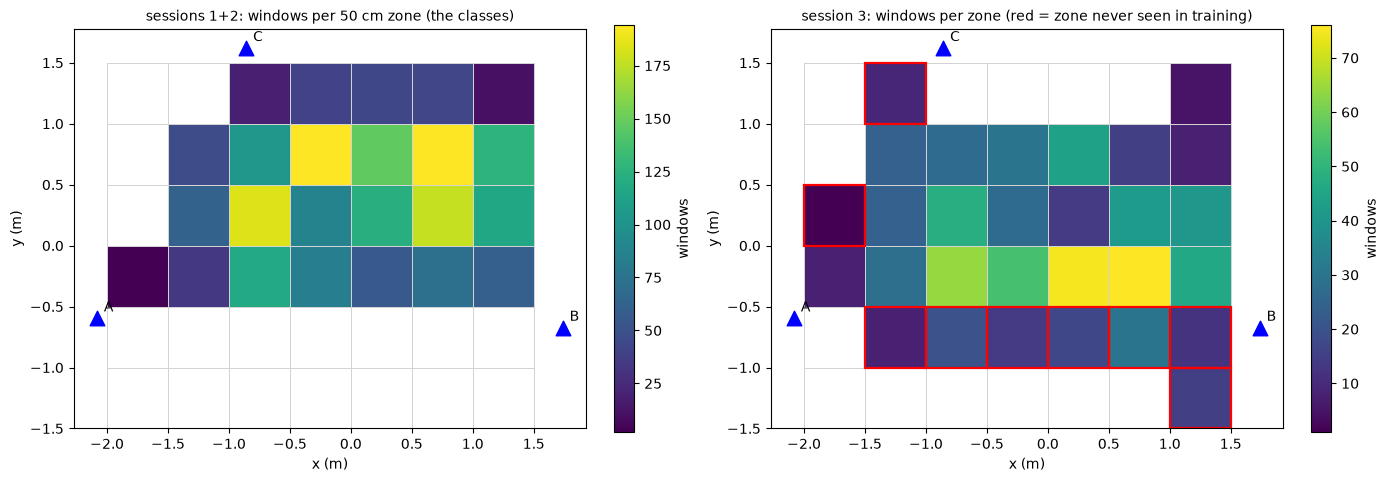

In [7]:
def zone_keys(xy, zs):    return np.floor(xy / zs + 1e-9).astype(int)                # (n, 2) integer cell indices
def zone_center(keys, zs): return (keys + 0.5) * zs                                    # (n, 2) meters

def make_classes(idx, zs):
    # the zones seen in these windows, and how many windows each has
    return np.unique(zone_keys(Y[idx], zs), axis=0, return_counts=True)

def labels_for(idx, classes, zs):
    # class index of each window's zone, or -1 if that zone is not among the classes
    d = {tuple(k): i for i, k in enumerate(classes)}
    return np.array([d.get(tuple(k), -1) for k in zone_keys(Y[idx], zs)])

def zone_metrics(probs, classes, idx, zs):
    keys = zone_keys(Y[idx], zs); lab = labels_for(idx, classes, zs)
    order = np.argsort(-probs, axis=1); pred = order[:, 0]; pk = classes[pred]
    top1 = pred == lab; seen = lab >= 0
    dist = np.linalg.norm(zone_center(pk, zs) - Y[idx], axis=1) * 100
    return dict(top1=float(top1.mean()), top3=float((order[:, :3] == lab[:, None]).any(1).mean()),
                within1=float((np.abs(pk - keys).max(1) <= 1).mean()), median_dist_cm=float(np.median(dist)),
                seen=float(seen.mean()), top1_seen=float(top1[seen].mean()) if seen.any() else float("nan"),
                pred_keys=pk, correct=top1, dist=dist, true_keys=keys, seen_mask=seen)

def extent(zs):
    k = np.concatenate([zone_keys(Y[fit_idx], zs), zone_keys(Y[te_idx], zs)])
    return k.min(0), k.max(0)

def grid_counts(idx, zs):
    lo_, hi_ = extent(zs); g = np.zeros((hi_[1] - lo_[1] + 1, hi_[0] - lo_[0] + 1))
    for kx, ky in zone_keys(Y[idx], zs): g[ky - lo_[1], kx - lo_[0]] += 1
    return g

def draw_grid(ax, zs, values, cmap, title, label, vmin=None, vmax=None, unseen=None):
    lo_, hi_ = extent(zs)
    xe, ye = np.arange(lo_[0], hi_[0] + 2) * zs, np.arange(lo_[1], hi_[1] + 2) * zs
    m = ax.pcolormesh(xe, ye, np.ma.masked_invalid(values), cmap=cmap, vmin=vmin, vmax=vmax, edgecolors="lightgray", linewidth=0.4)
    if unseen is not None:
        for kx, ky in unseen: ax.add_patch(plt.Rectangle((kx * zs, ky * zs), zs, zs, fill=False, ec="red", lw=1.6))
    for ph, (px, py) in ds.phones.items():
        ax.scatter(px, py, marker="^", s=110, c="b", zorder=5); ax.annotate(ph, (px, py), xytext=(5, 5), textcoords="offset points")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); plt.colorbar(m, ax=ax, label=label, fraction=0.04)

cfit, cnt_fit = make_classes(fit_idx, ZONE)
unseen_keys = [tuple(k) for k in np.unique(zone_keys(Y[te_idx], ZONE), axis=0) if tuple(k) not in {tuple(c) for c in cfit}]
lab_te = labels_for(te_idx, cfit, ZONE)
print(f"zone size {ZONE * 100:.0f} cm: {len(cfit)} zones seen in sessions 1+2 (final fit), median {int(np.median(cnt_fit))} windows per zone, min {cnt_fit.min()}")
print(f"session 3: {len(np.unique(zone_keys(Y[te_idx], ZONE), axis=0))} zones visited, {len(unseen_keys)} of them never seen in training; "
      f"{(lab_te < 0).sum()} of {len(te_idx)} test windows ({(lab_te < 0).mean():.0%}) are in unseen zones, so at most {(lab_te >= 0).mean():.0%} accuracy is reachable")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
g_tr = grid_counts(fit_idx, ZONE); g_te = grid_counts(te_idx, ZONE)
draw_grid(ax[0], ZONE, np.where(g_tr > 0, g_tr, np.nan), "viridis", f"sessions 1+2: windows per {ZONE * 100:.0f} cm zone (the classes)", "windows")
draw_grid(ax[1], ZONE, np.where(g_te > 0, g_te, np.nan), "viridis", "session 3: windows per zone (red = zone never seen in training)", "windows", unseen=unseen_keys)
plt.tight_layout()

## Training and evaluating a classifier
`fit_cls` trains a **fresh** network from scratch for a given number of epochs (cross-entropy on the zone index; standardisation from the training windows only; the raw-audio network gets the same random +-6 dB common gain as before) and returns the probability of every zone for the windows it is asked about. `run_model` does the whole protocol for one model: two seeds on the 80% part to find the epoch count with the best **validation accuracy** (smoothed over the epochs), a validation score from models trained on the 80% part, then a **final fit on all of sessions 1 and 2** (5 seeds for the MLP, 3 for the CNNs, probabilities averaged), the test score on session 3, and saving.

In [8]:
import json

def fit_cls(kind, make_net, Xa, la, Xb, epochs, seed, lb=None, keep=None):
    Xa = Xa.astype(np.float32); Xb = Xb.astype(np.float32)
    if kind == "flat":
        mu, sd = Xa.mean(0), Xa.std(0) + 1e-6; info = (mu, sd); bs, Opt, lr = 128, torch.optim.Adam, 3e-3
        norm = lambda x: (x - torch.tensor(mu)) / torch.tensor(sd)
    elif kind == "spec":
        mu, sd = Xa.mean((0, 3), keepdims=True), Xa.std((0, 3), keepdims=True) + 1e-6; info = (mu, sd); bs, Opt, lr = 64, torch.optim.AdamW, 2e-3
        norm = lambda x: (x - torch.tensor(mu)) / torch.tensor(sd)
    else:
        sd = float(Xa.std()); info = (sd,); bs, Opt, lr = 64, torch.optim.AdamW, 2e-3
        norm = lambda x: x / sd
    xa, xb, la_t = torch.tensor(Xa), torch.tensor(Xb), torch.tensor(la)
    torch.manual_seed(seed); net = make_net()
    opt = Opt(net.parameters(), lr=lr, weight_decay=1e-3)
    def predict():
        net.eval()
        with torch.no_grad():
            return torch.cat([F.softmax(net(norm(xb[i:i + 256])), 1) for i in range(0, len(xb), 256)]).numpy()
    acc, loss = [], []
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(xa))
        for s0 in range(0, len(xa), bs):
            b = perm[s0:s0 + bs]
            if len(b) < 2: continue
            xbatch = xa[b]
            if kind == "raw": xbatch = xbatch * (10 ** (torch.empty(len(b), 1, 1).uniform_(-6, 6) / 20))
            opt.zero_grad(); F.cross_entropy(net(norm(xbatch)), la_t[b]).backward(); opt.step()
        if lb is not None:
            p = predict(); seen = lb >= 0
            acc.append(float((p.argmax(1) == lb).mean())); loss.append(float(-np.log(p[seen, lb[seen]] + 1e-9).mean()))
    if keep is not None:
        keep.append(dict(state={k: v.detach().clone() for k, v in net.state_dict().items()}, norm=info))
    return predict(), dict(acc=acc, loss=loss)

RESULTS_JSON = SAVE_DIR / "results_zones.json"
all_results = {}
def scalar(m): return {k: v for k, v in m.items() if isinstance(v, float)}

def run_model(name, kind, builder, X, max_epochs, zs, final_seeds, smooth_k, save=True):
    ctr, _ = make_classes(tr_idx, zs); la, lb = labels_for(tr_idx, ctr, zs), labels_for(va_idx, ctr, zs)
    nparams = sum(p.numel() for p in builder(len(ctr)).parameters())
    print(f"{name}, zone {zs * 100:.0f} cm: {len(ctr)} classes in training, {nparams:,} parameters, {X[0].size:,} numbers per window")
    curves = [fit_cls(kind, lambda: builder(len(ctr)), X[tr_idx], la, X[va_idx], max_epochs, sd, lb)[1] for sd in (0, 1)]
    acc = np.mean([c["acc"] for c in curves], 0); loss = np.mean([c["loss"] for c in curves], 0)
    g = int(np.argmax(np.convolve(acc, np.ones(smooth_k) / smooth_k, "valid"))) + smooth_k // 2 + 1
    g = min(g, max_epochs)
    pv = np.mean([fit_cls(kind, lambda: builder(len(ctr)), X[tr_idx], la, X[va_idx], g, sd)[0] for sd in range(final_seeds)], axis=0)
    cf, _ = make_classes(fit_idx, zs); lf = labels_for(fit_idx, cf, zs); kp = []
    pt = np.mean([fit_cls(kind, lambda: builder(len(cf)), X[fit_idx], lf, X[te_idx], g, sd, keep=kp)[0] for sd in range(final_seeds)], axis=0)
    mv, mt = zone_metrics(pv, ctr, va_idx, zs), zone_metrics(pt, cf, te_idx, zs)
    r = dict(name=name, zs=zs, epochs=g, classes_tr=ctr, classes_fit=cf, val=mv, test=mt, probs_val=pv, probs_test=pt, acc_curve=acc, loss_curve=loss, params=nparams)
    print(f"   epochs={g}   validation: top-1 {mv['top1']:.0%}, within 1 cell {mv['within1']:.0%}, median distance {mv['median_dist_cm']:.0f} cm"
          f"   |   test: top-1 {mt['top1']:.0%} (on seen zones {mt['top1_seen']:.0%}), top-3 {mt['top3']:.0%}, within 1 cell {mt['within1']:.0%}, median distance {mt['median_dist_cm']:.0f} cm")
    tag = f"{name.replace(' ', '_').replace('-', '')}_zone{int(round(zs * 100))}cm"
    if save:
        torch.save(dict(name=name, zone_size_m=zs, classes=cf, epochs=g, members=kp, params=nparams, val=scalar(mv), test=scalar(mt)), SAVE_DIR / f"{tag}.pt")
        np.savez_compressed(SAVE_DIR / f"{tag}_probs.npz", probs_val=pv, probs_test=pt, classes_tr=ctr, classes_fit=cf, val_idx=va_idx, test_idx=te_idx)
        all_results[tag] = dict(name=name, zone_size_m=zs, epochs=g, params=nparams, classes=len(cf), val=scalar(mv), test=scalar(mt))
        json.dump(all_results, open(RESULTS_JSON, "w"), indent=1)
        print(f"   saved {tag}.pt, {tag}_probs.npz and updated {RESULTS_JSON.name}")
    return r

## Rough-guess baselines
Two guesses that ignore the audio, both using only how often each zone occurred in sessions 1 and 2:
* **Majority zone**: always answer the most common zone. (The analogue of the mean-position baseline.)
* **Random guess from the prior**: answer a random zone drawn with the training frequencies, as someone who knows the route but hears nothing. Its exact-match and within-one-cell scores are computed as expectations; its distance by 200 random draws.

For reference the uniform chance level is one over the number of zones.

In [9]:
def baselines(zs):
    cf, cnt = make_classes(fit_idx, zs); prior = cnt / cnt.sum()
    maj = zone_metrics(np.tile(prior, (len(te_idx), 1)), cf, te_idx, zs)                   # argmax of the prior = the majority zone
    ctr, cnt_tr = make_classes(tr_idx, zs)
    maj_val = zone_metrics(np.tile(cnt_tr / cnt_tr.sum(), (len(va_idx), 1)), ctr, va_idx, zs)
    kt = zone_keys(Y[te_idx], zs); d = np.abs(cf[None, :, :] - kt[:, None, :]).max(2)       # cell distance of every test window to every class
    rng = np.random.default_rng(0); draws = rng.choice(len(cf), size=(200, len(te_idx)), p=prior)
    dist = np.linalg.norm(zone_center(cf[draws], zs) - Y[te_idx], axis=2) * 100
    return dict(majority=maj, majority_val=maj_val, prior_top1=float(((d == 0) * prior).sum(1).mean()), prior_within1=float(((d <= 1) * prior).sum(1).mean()),
                prior_median_dist_cm=float(np.mean(np.median(dist, 1))), uniform=1 / len(cf), n_classes=len(cf))

base = baselines(ZONE); bm = base["majority"]
print(f"zone size {ZONE * 100:.0f} cm, {base['n_classes']} classes (uniform chance {base['uniform']:.1%})")
print(f"majority zone:        test top-1 {bm['top1']:.1%}, within 1 cell {bm['within1']:.0%}, median distance {bm['median_dist_cm']:.0f} cm   (validation top-1 {base['majority_val']['top1']:.1%})")
print(f"random guess (prior): test top-1 {base['prior_top1']:.1%}, within 1 cell {base['prior_within1']:.0%}, median distance {base['prior_median_dist_cm']:.0f} cm")
all_results["baselines_50cm"] = dict(zone_size_m=ZONE, classes=base["n_classes"], majority_test=scalar(bm), majority_val=scalar(base["majority_val"]),
                                      prior=dict(top1=base["prior_top1"], within1=base["prior_within1"], median_dist_cm=base["prior_median_dist_cm"]), uniform=base["uniform"])
json.dump(all_results, open(RESULTS_JSON, "w"), indent=1)

zone size 50 cm, 24 classes (uniform chance 4.2%)
majority zone:        test top-1 3.6%, within 1 cell 23%, median distance 118 cm   (validation top-1 6.1%)
random guess (prior): test top-1 4.1%, within 1 cell 29%, median distance 119 cm


## The three models at the main zone size (weights and predictions are saved as each one finishes)

In [10]:
res = {}
res["8-band MLP"] = run_model("8-band MLP", "flat", lambda k: make_mlp_cls(X_band.shape[1], k), X_band, MAXE["mlp"], ZONE, 5, 5)

8-band MLP, zone 50 cm: 24 classes in training, 7,320 parameters, 24 numbers per window


   epochs=36   validation: top-1 31%, within 1 cell 79%, median distance 41 cm   |   test: top-1 21% (on seen zones 25%), top-3 45%, within 1 cell 66%, median distance 60 cm
   saved 8band_MLP_zone50cm.pt, 8band_MLP_zone50cm_probs.npz and updated results_zones.json


In [11]:
res["log-mel CNN"] = run_model("log-mel CNN", "spec", make_spec_cnn, S, MAXE["spec"], ZONE, 3, 3)

log-mel CNN, zone 50 cm: 24 classes in training, 9,240 parameters, 9,696 numbers per window


   epochs=41   validation: top-1 35%, within 1 cell 85%, median distance 37 cm   |   test: top-1 27% (on seen zones 32%), top-3 52%, within 1 cell 74%, median distance 49 cm
   saved logmel_CNN_zone50cm.pt, logmel_CNN_zone50cm_probs.npz and updated results_zones.json


In [12]:
res["raw-audio CNN"] = run_model("raw-audio CNN", "raw", make_raw_cnn, X_raw, MAXE["raw"], ZONE, 3, 3)

raw-audio CNN, zone 50 cm: 24 classes in training, 11,736 parameters, 48,000 numbers per window


   epochs=28   validation: top-1 24%, within 1 cell 75%, median distance 49 cm   |   test: top-1 15% (on seen zones 17%), top-3 34%, within 1 cell 58%, median distance 69 cm
   saved rawaudio_CNN_zone50cm.pt, rawaudio_CNN_zone50cm_probs.npz and updated results_zones.json


## Zone-size sweep (cheap models only)
The baselines and the 8-band MLP at several zone sizes, everything else unchanged. Smaller cells are harder to get exactly right and have more classes with fewer windows each; larger cells are easier but say less about where the speaker is.

In [13]:
sweep = {}
for zs in ZONE_SWEEP:
    b = baselines(zs)
    r = res["8-band MLP"] if zs == ZONE else run_model("8-band MLP", "flat", lambda k: make_mlp_cls(X_band.shape[1], k), X_band, MAXE["mlp"], zs, 5, 5)
    sweep[zs] = dict(base=b, mlp=r)

8-band MLP, zone 25 cm: 75 classes in training, 10,635 parameters, 24 numbers per window


   epochs=15   validation: top-1 14%, within 1 cell 51%, median distance 39 cm   |   test: top-1 6% (on seen zones 9%), top-3 17%, within 1 cell 34%, median distance 59 cm
   saved 8band_MLP_zone25cm.pt, 8band_MLP_zone25cm_probs.npz and updated results_zones.json
8-band MLP, zone 75 cm: 13 classes in training, 6,605 parameters, 24 numbers per window


   epochs=38   validation: top-1 43%, within 1 cell 92%, median distance 48 cm   |   test: top-1 31% (on seen zones 32%), top-3 64%, within 1 cell 83%, median distance 63 cm
   saved 8band_MLP_zone75cm.pt, 8band_MLP_zone75cm_probs.npz and updated results_zones.json
8-band MLP, zone 100 cm: 11 classes in training, 6,475 parameters, 24 numbers per window


   epochs=15   validation: top-1 53%, within 1 cell 97%, median distance 55 cm   |   test: top-1 36% (on seen zones 37%), top-3 69%, within 1 cell 90%, median distance 72 cm
   saved 8band_MLP_zone100cm.pt, 8band_MLP_zone100cm_probs.npz and updated results_zones.json


  zone  classes  majority   prior  MLP top-1  MLP seen-only  within 1  distance cm  reachable
   25c       76      0.7%    1.1%       6.4%           9.0%       34%           59        71%
   50c       24      3.6%    4.1%      21.4%          25.3%       66%           60        85%
   75c       13     10.3%    7.8%      30.9%          31.8%       83%           63        97%
  100c       11     13.9%   12.8%      36.2%          37.3%       90%           72        97%


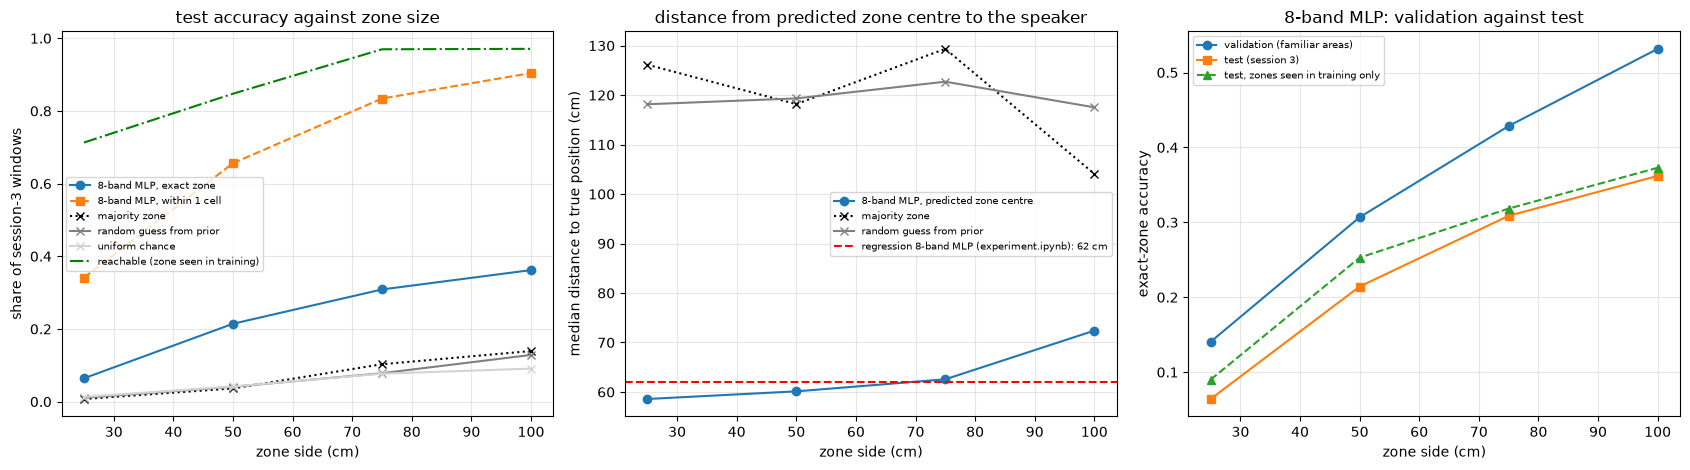

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
zs_list = sorted(sweep); xs = [z * 100 for z in zs_list]
for key, lab, st in (("top1", "8-band MLP, exact zone", "o-"), ("within1", "8-band MLP, within 1 cell", "s--")):
    ax[0].plot(xs, [sweep[z]["mlp"]["test"][key] for z in zs_list], st, label=lab)
ax[0].plot(xs, [sweep[z]["base"]["majority"]["top1"] for z in zs_list], "k:", marker="x", label="majority zone")
ax[0].plot(xs, [sweep[z]["base"]["prior_top1"] for z in zs_list], "-", c="gray", marker="x", label="random guess from prior")
ax[0].plot(xs, [sweep[z]["base"]["uniform"] for z in zs_list], "-", c="lightgray", marker="x", label="uniform chance")
ax[0].plot(xs, [sweep[z]["mlp"]["test"]["seen"] for z in zs_list], "g-.", label="reachable (zone seen in training)")
ax[0].set_xlabel("zone side (cm)"); ax[0].set_ylabel("share of session-3 windows"); ax[0].set_title("test accuracy against zone size"); ax[0].legend(fontsize=7); ax[0].grid(alpha=0.3)
ax[1].plot(xs, [sweep[z]["mlp"]["test"]["median_dist_cm"] for z in zs_list], "o-", label="8-band MLP, predicted zone centre")
ax[1].plot(xs, [sweep[z]["base"]["majority"]["median_dist_cm"] for z in zs_list], "k:", marker="x", label="majority zone")
ax[1].plot(xs, [sweep[z]["base"]["prior_median_dist_cm"] for z in zs_list], "-", c="gray", marker="x", label="random guess from prior")
reg = json.load(open("trained_models/summary.json"))["models"]["8-band_mlp"]["test_median_cm"]
ax[1].axhline(reg, c="r", ls="--", label=f"regression 8-band MLP (experiment.ipynb): {reg:.0f} cm")
ax[1].set_xlabel("zone side (cm)"); ax[1].set_ylabel("median distance to true position (cm)"); ax[1].set_title("distance from predicted zone centre to the speaker"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
ax[2].plot(xs, [sweep[z]["mlp"]["val"]["top1"] for z in zs_list], "o-", label="validation (familiar areas)")
ax[2].plot(xs, [sweep[z]["mlp"]["test"]["top1"] for z in zs_list], "s-", label="test (session 3)")
ax[2].plot(xs, [sweep[z]["mlp"]["test"]["top1_seen"] for z in zs_list], "^--", label="test, zones seen in training only")
ax[2].set_xlabel("zone side (cm)"); ax[2].set_ylabel("exact-zone accuracy"); ax[2].set_title("8-band MLP: validation against test"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)
plt.tight_layout()
print(f"{'zone':>6}{'classes':>9}{'majority':>10}{'prior':>8}{'MLP top-1':>11}{'MLP seen-only':>15}{'within 1':>10}{'distance cm':>13}{'reachable':>11}")
for z in zs_list:
    m = sweep[z]["mlp"]["test"]; b = sweep[z]["base"]
    print(f"{z * 100:5.0f}c{b['n_classes']:9}{b['majority']['top1']:10.1%}{b['prior_top1']:8.1%}{m['top1']:11.1%}{m['top1_seen']:15.1%}{m['within1']:10.0%}{m['median_dist_cm']:13.0f}{m['seen']:11.0%}")

## Results at the main zone size (50 cm)

In [15]:
names = ["8-band MLP", "log-mel CNN", "raw-audio CNN"]
print(f"{'':<26}{'val top-1':>10}{'test top-1':>11}{'seen-only':>10}{'top-3':>7}{'within 1':>9}{'distance cm':>12}{'epochs':>8}{'params':>9}")
print(f"{'majority zone':<26}{base['majority_val']['top1']:10.1%}{bm['top1']:11.1%}{bm['top1_seen']:10.1%}{bm['top3']:7.0%}{bm['within1']:9.0%}{bm['median_dist_cm']:12.0f}")
print(f"{'random guess (prior)':<26}{'':>10}{base['prior_top1']:11.1%}{'':>10}{'':>7}{base['prior_within1']:9.0%}{base['prior_median_dist_cm']:12.0f}")
for n in sorted(names, key=lambda k: -res[k]["val"]["top1"]):
    r = res[n]; m = r["test"]
    print(f"{n:<26}{r['val']['top1']:10.1%}{m['top1']:11.1%}{m['top1_seen']:10.1%}{m['top3']:7.0%}{m['within1']:9.0%}{m['median_dist_cm']:12.0f}{r['epochs']:8}{r['params']:9,}")
headline = max(names, key=lambda k: res[k]["val"]["top1"])
print("\nheadline (best validation accuracy):", headline)
print(f"reachable share of the test (zone seen in training): {res[headline]['test']['seen']:.0%}")

                           val top-1 test top-1 seen-only  top-3 within 1 distance cm  epochs   params
majority zone                   6.1%       3.6%      4.3%    11%      23%         118
random guess (prior)                       4.1%                       29%         119
log-mel CNN                    34.9%      26.8%     31.6%    52%      74%          49      41    9,240
8-band MLP                     30.7%      21.4%     25.3%    45%      66%          60      36    7,320
raw-audio CNN                  24.4%      14.8%     17.4%    34%      58%          69      28   11,736

headline (best validation accuracy): log-mel CNN
reachable share of the test (zone seen in training): 85%


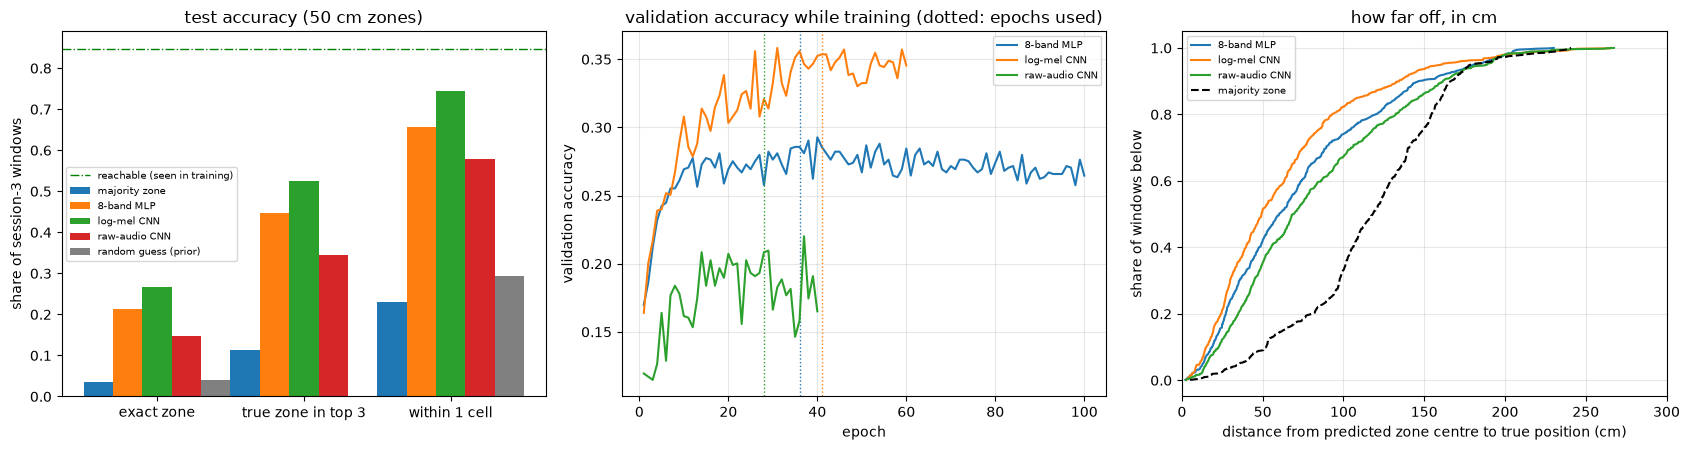

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
rows = [("majority zone", bm), ("8-band MLP", res["8-band MLP"]["test"]), ("log-mel CNN", res["log-mel CNN"]["test"]), ("raw-audio CNN", res["raw-audio CNN"]["test"])]
w = 0.2; xs_ = np.arange(3)
for j, (lab, m) in enumerate(rows):
    ax[0].bar(xs_ + j * w, [m["top1"], m["top3"], m["within1"]], w, label=lab)
ax[0].bar(xs_[0] + 4 * w, base["prior_top1"], w, color="gray", label="random guess (prior)"); ax[0].bar(xs_[2] + 4 * w, base["prior_within1"], w, color="gray")
ax[0].axhline(res[headline]["test"]["seen"], c="g", ls="-.", lw=1, label="reachable (seen in training)")
ax[0].set_xticks(xs_ + 2 * w); ax[0].set_xticklabels(["exact zone", "true zone in top 3", "within 1 cell"]); ax[0].set_ylabel("share of session-3 windows"); ax[0].legend(fontsize=7); ax[0].set_title("test accuracy (50 cm zones)")
for n in names:
    ax[1].plot(np.arange(1, len(res[n]["acc_curve"]) + 1), res[n]["acc_curve"], label=n)
    ax[1].axvline(res[n]["epochs"], c=ax[1].lines[-1].get_color(), ls=":", lw=1)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy"); ax[1].set_title("validation accuracy while training (dotted: epochs used)"); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
for n in names:
    e = np.sort(res[n]["test"]["dist"]); ax[2].plot(e, np.arange(1, len(e) + 1) / len(e), label=n)
e = np.sort(bm["dist"]); ax[2].plot(e, np.arange(1, len(e) + 1) / len(e), "k--", label="majority zone")
ax[2].set_xlim(0, 300); ax[2].set_xlabel("distance from predicted zone centre to true position (cm)"); ax[2].set_ylabel("share of windows below"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3); ax[2].set_title("how far off, in cm")
plt.tight_layout()

### Per model: where it is right, and the track
Left: for each zone, the share of the session-3 windows in it that the model got right (white = no windows; red outline = zone never seen in training, so unreachable). Right: session 3's true track (black) against the **centres of the predicted zones** (red dots and thin line, one per window; green = the answer was exactly right).

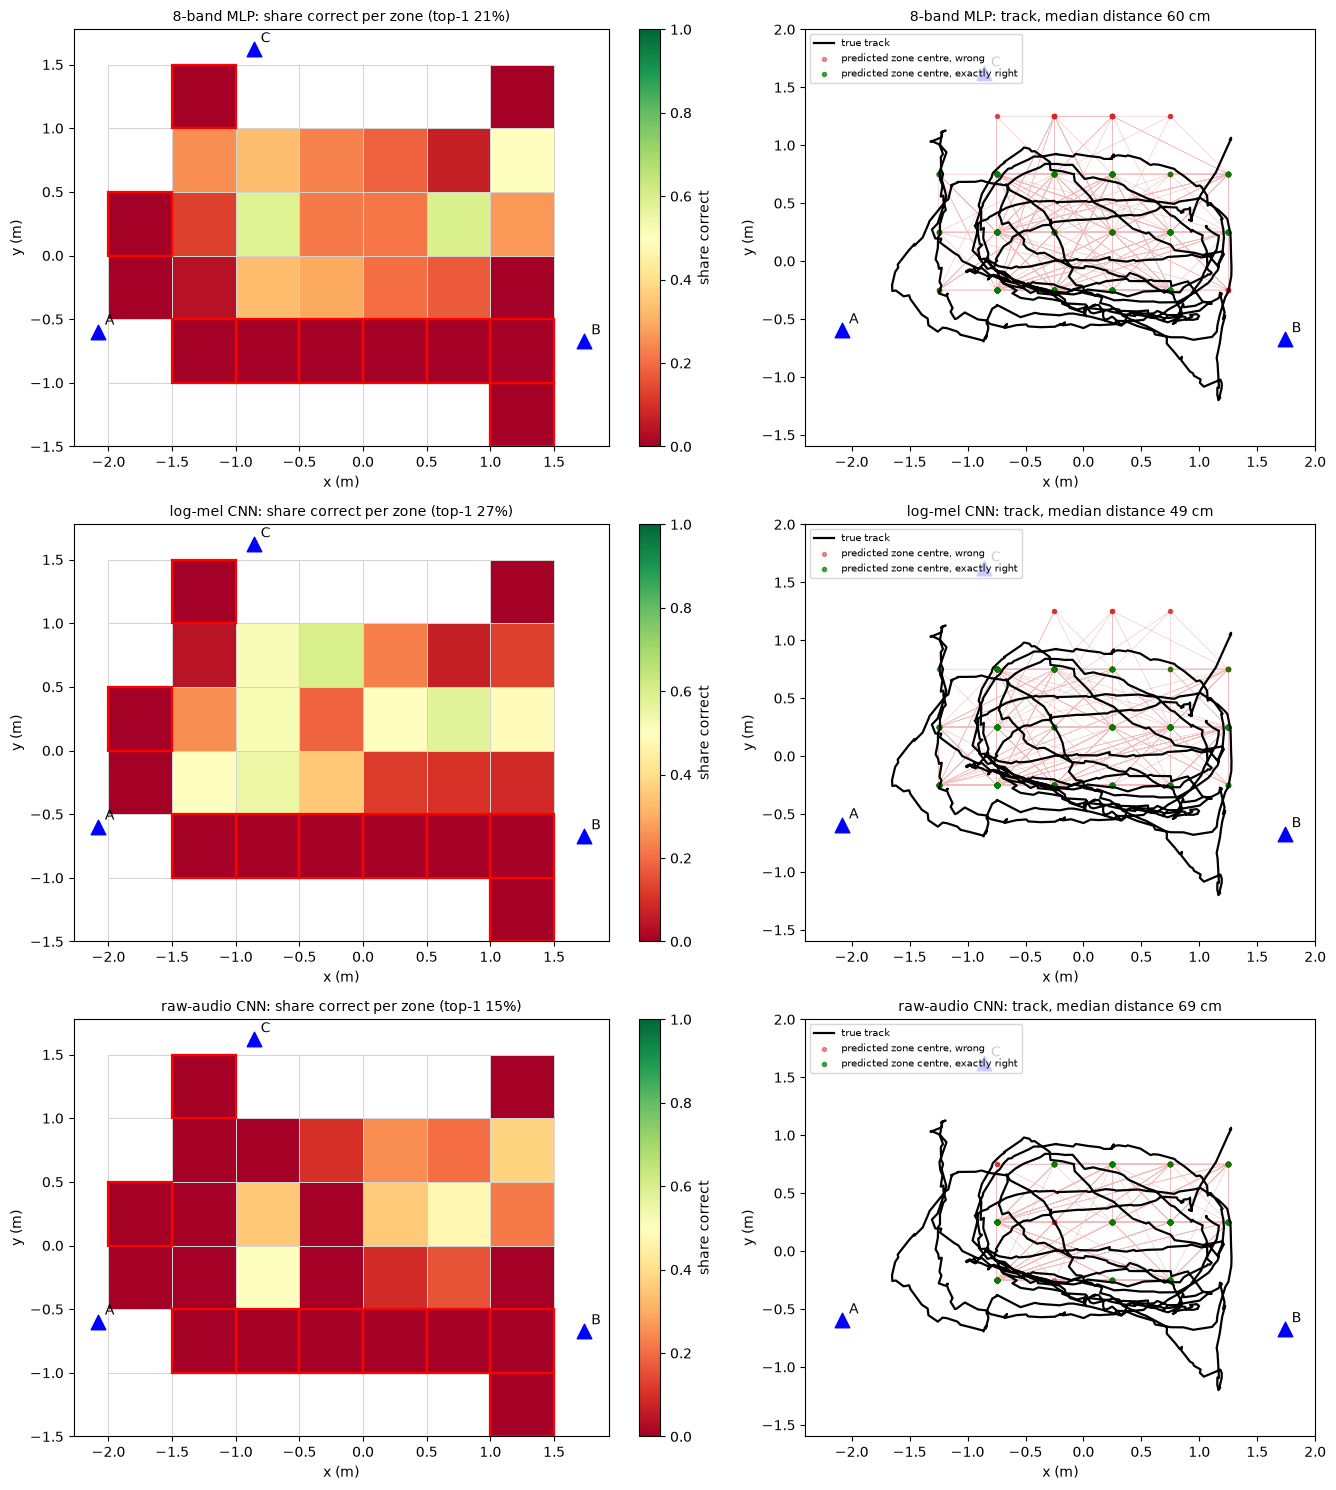

In [17]:
fig, ax = plt.subplots(3, 2, figsize=(14, 15))
for row, n in zip(ax, names):
    t = res[n]["test"]; lo_, hi_ = extent(ZONE)
    g_ok = np.zeros((hi_[1] - lo_[1] + 1, hi_[0] - lo_[0] + 1)); g_n = np.zeros_like(g_ok)
    for (kx, ky), ok in zip(t["true_keys"], t["correct"]):
        g_n[ky - lo_[1], kx - lo_[0]] += 1; g_ok[ky - lo_[1], kx - lo_[0]] += ok
    draw_grid(row[0], ZONE, np.where(g_n > 0, g_ok / np.maximum(g_n, 1), np.nan), "RdYlGn", f"{n}: share correct per zone (top-1 {t['top1']:.0%})", "share correct", 0, 1, unseen_keys)
    pc = zone_center(t["pred_keys"], ZONE)
    row[1].plot(*Y[te_idx].T, "k-", lw=1.6, label="true track", zorder=3)
    row[1].plot(*pc.T, "-", c="tab:red", lw=0.4, alpha=0.3, zorder=1)
    row[1].scatter(*pc[~t["correct"]].T, s=8, c="tab:red", alpha=0.5, label="predicted zone centre, wrong", zorder=2)
    row[1].scatter(*pc[t["correct"]].T, s=9, c="green", alpha=0.7, label="predicted zone centre, exactly right", zorder=2)
    for ph, (px, py) in ds.phones.items():
        row[1].scatter(px, py, marker="^", s=110, c="b", zorder=5); row[1].annotate(ph, (px, py), xytext=(5, 5), textcoords="offset points")
    row[1].set_aspect("equal"); row[1].set_xlim(-2.4, 2.0); row[1].set_ylim(-1.6, 2.0); row[1].legend(fontsize=7, loc="upper left")
    row[1].set_title(f"{n}: track, median distance {t['median_dist_cm']:.0f} cm", fontsize=10); row[1].set_xlabel("x (m)"); row[1].set_ylabel("y (m)")
plt.tight_layout()

### Confusion matrix of the headline model
Rows: the true zone of session-3 windows (only zones seen in training; windows in unseen zones cannot be right and are left out here). Columns: the predicted zone. Each row is normalised to 1 (diagonal = correct); the number in each cell is the count. Zone labels are `(ix, iy)` cell indices, sorted by ix then iy.

of the 700 test windows in seen zones: 32% in the right zone, 50% one cell away, 9% two cells away, 9% three or more


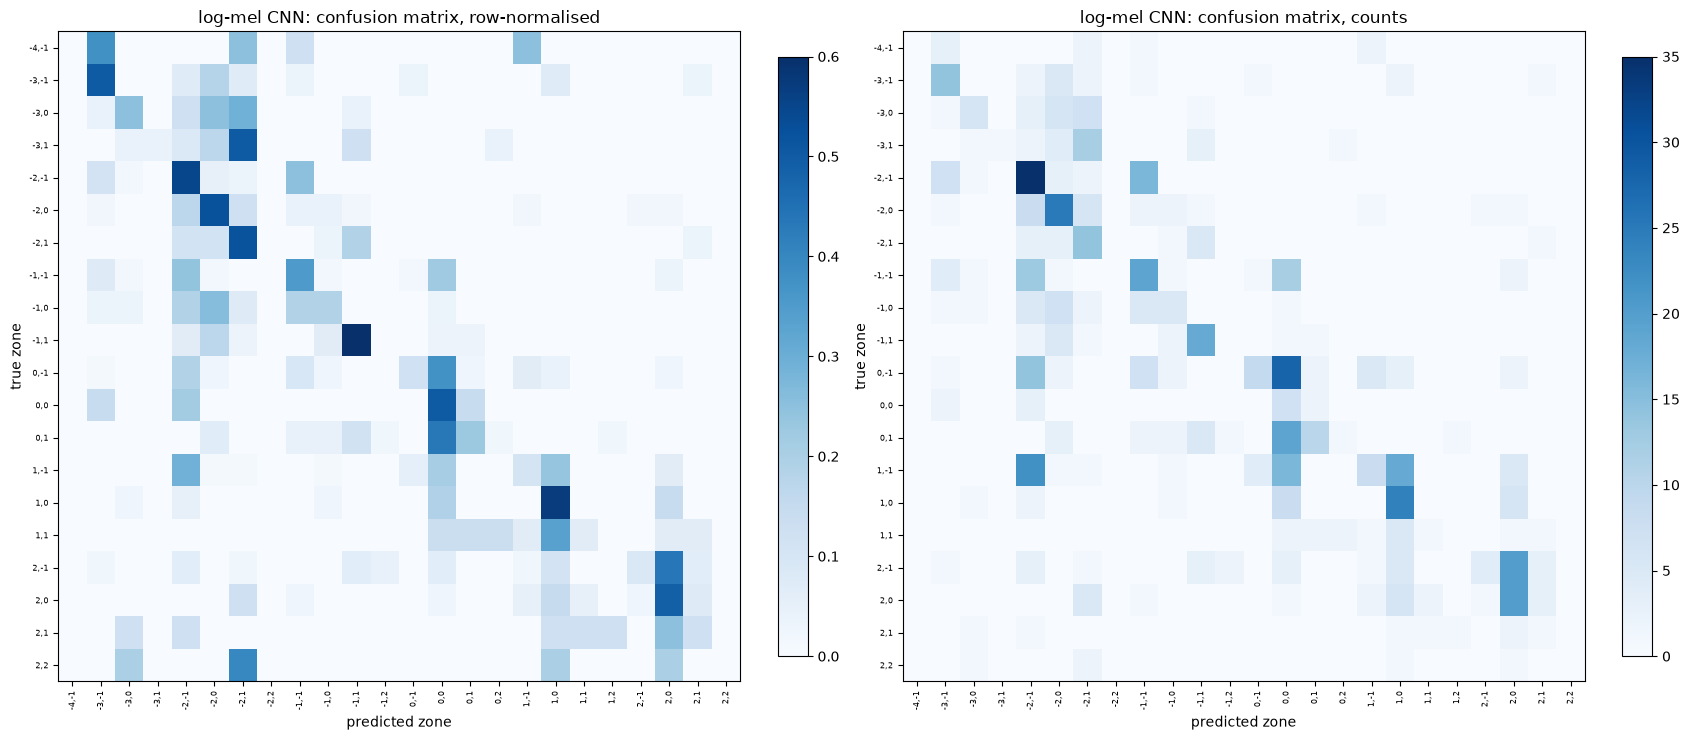

In [18]:
t = res[headline]["test"]; cf = res[headline]["classes_fit"]; K = len(cf)
lab = labels_for(te_idx, cf, ZONE); sel = lab >= 0
pred_idx = np.argmax(res[headline]["probs_test"], axis=1)
cm = np.zeros((K, K), int)
for a, b in zip(lab[sel], pred_idx[sel]): cm[a, b] += 1
rows_used = cm.sum(1) > 0
fig, ax = plt.subplots(1, 2, figsize=(17, 7.5))
for a, (mat, title) in zip(ax, ((cm[rows_used] / np.maximum(cm[rows_used].sum(1, keepdims=True), 1), "row-normalised"), (cm[rows_used], "counts"))):
    im = a.imshow(mat, cmap="Blues", aspect="auto"); plt.colorbar(im, ax=a, fraction=0.04)
    a.set_xticks(range(K)); a.set_xticklabels([f"{k[0]},{k[1]}" for k in cf], rotation=90, fontsize=6)
    a.set_yticks(range(rows_used.sum())); a.set_yticklabels([f"{k[0]},{k[1]}" for k in cf[rows_used]], fontsize=6)
    a.set_xlabel("predicted zone"); a.set_ylabel("true zone"); a.set_title(f"{headline}: confusion matrix, {title}")
plt.tight_layout()
off = np.abs(cf[pred_idx[sel]] - cf[lab[sel]]).max(1)
print(f"of the {sel.sum()} test windows in seen zones: {np.mean(off == 0):.0%} in the right zone, {np.mean(off == 1):.0%} one cell away, {np.mean(off == 2):.0%} two cells away, {np.mean(off >= 3):.0%} three or more")

## Files written
* `trained_models_zones/<model>_zone<size>cm.pt`: for every seed of the final fit, the network weights and the standardisation numbers; the zone classes (the order of the output scores), the epoch count, parameter count and the scores. The architectures are `make_mlp_cls`, `make_spec_cnn`, `make_raw_cnn` above (the last layer has one output per class).
* `trained_models_zones/<model>_zone<size>cm_probs.npz`: the predicted probability of every zone for the validation and test windows (`probs_val`, `probs_test`), the class lists (`classes_tr` for the validation run, `classes_fit` for the final fit) and the window indices in the dataset's order.
* `trained_models_zones/results_zones.json`: all scores, updated after every model.

## Notes
* Same protocol as `experiment.ipynb`, so the numbers can be compared with it; the regression result for the 8-band MLP (median error 62 cm) is read from `trained_models/summary.json` for the reference line in the sweep figure.
* Session 3 is one session; differences of a few percentage points between models are noise (see the discussion in `experiment.ipynb`).